# Merchants and categories in SynCCFD

This notebook shows the merchants of SynCCFD. With `MerchantConfig`, the amount and the time
of a purchase depend on the merchant's **category**, not only on the customer:

- terminals belong to physical merchants (1 to a few terminals, in the same city); online
  merchants (CNP) have one virtual terminal at their head office;
- each customer has a preference over the categories, $\mathrm{Dirichlet}(\alpha \cdot
  \text{weights})$, and a spending factor, $\mathrm{LogNormal}(0, 0.5)$;
- a purchase draws the category from the preference (with the weekend factor), the type
  (CP, CNP; in mixed categories, the online fraction of the category combined with the
  customer's propensity), the merchant (a favourite with probability 0.6), the hour (profile
  of the category; CP only in opening hours) and the amount,
  $\text{median}_{\text{category}} \times \text{factor}_{\text{customer}} \times
  \mathrm{LogNormal}(0, \sigma_{\text{category}})$.

The category names (`supermercado`, `eletronicos`, ...) are values of the data, and stay as
they are in the tables below.

`LANG` is the language of the figure labels: `"en"` (default) or `"pt"`; the environment
variable `SYNCCFD_LANG` sets it. The figures are saved as PDF in `figures/merchants/`
(`SYNCCFD_FIG_DIR` changes `figures/`).

In [1]:
import os
import re
from pathlib import Path

# Fixed creation date in the PDF files: an unchanged figure is written byte for byte
# the same
os.environ.setdefault("SOURCE_DATE_EPOCH", "0")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import ticker

from synccfd import DatasetGenerator
from synccfd.simulator import presets
from synccfd.simulator.config import DEFAULT_CATEGORIES

# Language of the figure labels: "en" or "pt"
LANG = os.environ.get("SYNCCFD_LANG", "en")
TEXT = {
    "en": {
        "categories": {
            "supermercado": "supermarket", "restaurante_bar": "restaurant and bar",
            "posto_combustivel": "fuel station", "farmacia": "pharmacy",
            "vestuario": "clothing", "eletronicos": "electronics", "viagem_turismo": "travel",
            "ecommerce_marketplace": "marketplace", "servicos_digitais": "digital services",
            "transporte_app": "ride-hailing",
        },
        "channels": {"CP": "CP only", "CNP": "CNP only", "CP+CNP": "CP and CNP"},
        "boxes_note": "amount (R$, log scale); boxes: quartiles; whiskers: up to 1.5 × IQR (in log)",
        "configured_median": "configured median",
        "hour_of_day": "hour of the day",
        "share_of_category": "% of the category's purchases",
        "opening_note": "Outline: opening hours (CP purchases).",
        "share_of_tx": "% of the transactions",
        "configured_weight": "configured weight",
    },
    "pt": {
        "categories": {
            "supermercado": "supermercado", "restaurante_bar": "restaurante e bar",
            "posto_combustivel": "posto de combustível", "farmacia": "farmácia",
            "vestuario": "vestuário", "eletronicos": "eletrônicos", "viagem_turismo": "viagem e turismo",
            "ecommerce_marketplace": "e-commerce e marketplace", "servicos_digitais": "serviços digitais",
            "transporte_app": "transporte por app",
        },
        "channels": {"CP": "só CP", "CNP": "só CNP", "CP+CNP": "CP e CNP"},
        "boxes_note": "valor (R$, escala log); caixas: quartis; hastes: até 1,5 × IQR (em log)",
        "configured_median": "mediana configurada",
        "hour_of_day": "hora do dia",
        "share_of_category": "% das compras da categoria",
        "opening_note": "Contorno: horário de funcionamento (compras CP).",
        "share_of_tx": "% das transações",
        "configured_weight": "peso configurado",
    },
}
T = TEXT[LANG]

# Where the figures are saved
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "figures")) / "merchants"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = {c.name: c for c in DEFAULT_CATEGORIES}
LABELS = T["categories"]
CHANNEL_LABELS = T["channels"]
# One color per channel (validated palette, fixed order); ink for text
CHANNEL_COLORS = {"CP": "#2a78d6", "CP+CNP": "#1baf7a", "CNP": "#eb6834"}
MUTED, INK, SECONDARY = "#8a8985", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

# In Portuguese, the numbers in the figures use the decimal comma and a space between
# the thousands, as in the text of the dissertation
def num(text):
    if LANG != "pt":
        return text
    math = text.count("$") >= 2  # mathtext: braces keep the comma without a space
    point, thousands = ("{,}", r"\,") if math else (",", "\u00a0")
    return re.sub(r"(?<=\d)[.,](?=\d)", lambda m: point if m.group() == "." else thousands, text)


class LocalizedFormatter(ticker.Formatter):
    # The labels of another tick formatter, through num()
    def __init__(self, inner):
        self.inner = inner

    def set_axis(self, axis):
        self.axis = axis
        self.inner.set_axis(axis)

    def set_locs(self, locs):
        self.inner.set_locs(locs)

    def __call__(self, x, pos=None):
        return num(self.inner(x, pos))

    def format_ticks(self, values):
        return [num(label) for label in self.inner.format_ticks(values)]

    def get_offset(self):
        return num(self.inner.get_offset())


def localize(fig):
    # The tick labels of every axis through num(); call it just before saving
    if LANG != "pt":
        return
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if not isinstance(axis.get_major_formatter(), LocalizedFormatter):
                axis.set_major_formatter(LocalizedFormatter(axis.get_major_formatter()))
            if not isinstance(axis.get_minor_formatter(), LocalizedFormatter):
                axis.set_minor_formatter(LocalizedFormatter(axis.get_minor_formatter()))

## The categories

The default values (`DEFAULT_CATEGORIES`), chosen as in the paper: reasonable, but not
calibrated on real data.

In [2]:
pd.DataFrame([
    {"category": c.name, "channel": c.channel, "median (R$)": c.median_amount, "log σ": c.log_sigma,
     "weight": c.weight,
     "online fraction": c.online_fraction if c.channel == "CP+CNP" else None, "CP hours": f"{c.opening_hours[0]}–{c.opening_hours[1]} h" if c.has_cp else "-",
     "weekend": c.weekend_factor, "skimming risk": c.skimming_risk if c.has_cp else None}
    for c in DEFAULT_CATEGORIES
]).set_index("category")

,channel,median (R$),log σ,weight,online fraction,CP hours,weekend,skimming risk
category,,,,,,,,
supermercado,CP+CNP,120,0.7,0.20,0.10,8–21 h,1.2,1.0
restaurante_bar,CP,60,0.6,0.15,NaN,11–24 h,1.4,2.0
posto_combustivel,CP,150,0.4,0.10,NaN,6–23 h,1.0,3.0
farmacia,CP+CNP,70,0.6,0.08,0.15,8–22 h,1.0,1.0
vestuario,CP+CNP,180,0.7,0.08,0.30,10–22 h,1.3,1.0
eletronicos,CP+CNP,900,0.8,0.04,0.50,10–22 h,1.1,1.0
viagem_turismo,CNP,1200,0.7,0.03,NaN,-,1.0,NaN
ecommerce_marketplace,CNP,150,0.9,0.15,NaN,-,1.1,NaN
servicos_digitais,CNP,35,0.5,0.10,NaN,-,1.0,NaN


## Generation

The dataset is `presets.realistic()`, with merchants, drift, seasonality and injected
frauds. The figures only use the legitimate transactions (frauds buy in the categories of
each scenario; see `examples/frauds.ipynb`).

In [3]:
# The preset of the notebooks; the SYNCCFD_* variables change it
PARAMS = presets.from_env()
assert PARAMS.get("merchants") is not None, "this notebook needs a preset with merchants"
N_CUSTOMERS, N_TERMINALS, NB_DAYS = (PARAMS[k] for k in ("n_customers", "n_terminals", "nb_days"))

generator = DatasetGenerator(**PARAMS)
customers, terminals, all_transactions = generator.generate()
transactions = all_transactions[all_transactions.TX_FRAUD == 0]
merchants = generator.merchant_profiles
print(f"{len(transactions):,} legitimate transactions, {len(merchants):,} merchants "
      f"({(merchants.channel == 'CP').sum():,} physical, {(merchants.channel == 'CNP').sum()} online)")
merchants.groupby(["MERCHANT_CATEGORY", "channel"]).agg(
    merchants=("MERCHANT_ID", "size"), terminals=("n_terminals", "sum")
).unstack(fill_value=0)

3,722,147 legitimate transactions, 14,165 merchants (14,005 physical, 160 online)


merchants       terminals      
channel                     CNP    CP       CNP    CP
MERCHANT_CATEGORY                                    
ecommerce_marketplace        20     0        20     0
eletronicos                  20   851        20  1212
farmacia                     20  1724        20  2499
posto_combustivel             0  2185         0  3096
restaurante_bar               0  3274         0  4664
servicos_digitais            20     0        20     0
supermercado                 20  4241        20  6044
transporte_app               20     0        20     0
vestuario                    20  1730        20  2485
viagem_turismo               20     0        20     0

## Amount per category

Distribution of the amounts of each category (log scale). The diamond marks the configured
median; the color shows the channel of the category.

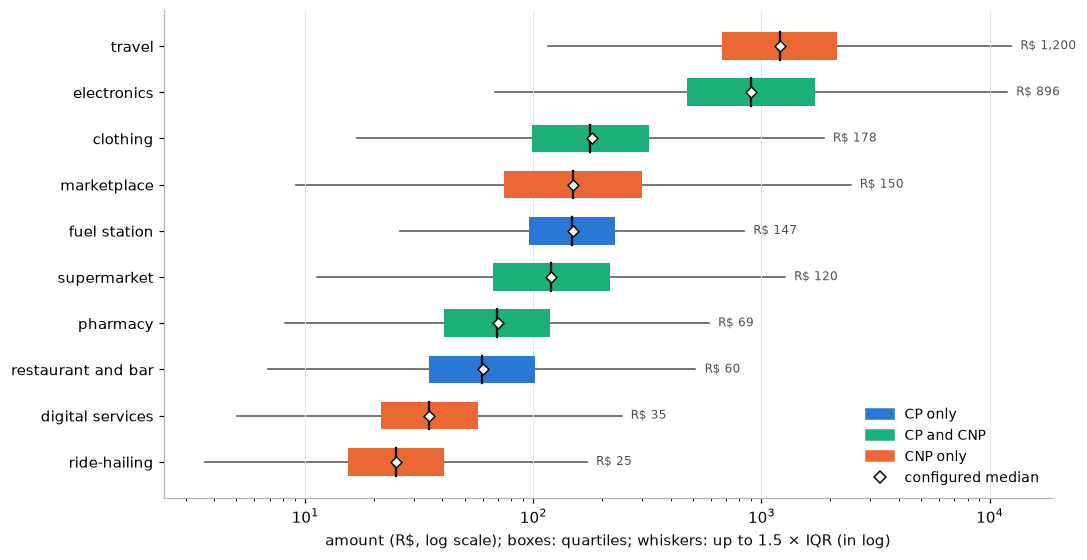

,observed_median,configured,difference_pct
MERCHANT_CATEGORY,,,
ecommerce_marketplace,149.66,150,-0.2
eletronicos,896.41,900,-0.4
farmacia,69.34,70,-0.9
posto_combustivel,147.13,150,-1.9
restaurante_bar,59.51,60,-0.8
servicos_digitais,35.08,35,0.2
supermercado,119.67,120,-0.3
transporte_app,24.93,25,-0.3
vestuario,177.83,180,-1.2


In [4]:
order = sorted(CATEGORIES, key=lambda name: CATEGORIES[name].median_amount)
fig, ax = plt.subplots(figsize=(10, 5.2))
for i, name in enumerate(order):
    category = CATEGORIES[name]
    values = transactions.loc[transactions.MERCHANT_CATEGORY == name, "TX_AMOUNT"]
    logs = np.log10(values[values > 0])
    q1, median, q3 = np.quantile(logs, [0.25, 0.5, 0.75])
    low = logs[logs >= q1 - 1.5 * (q3 - q1)].min()
    high = logs[logs <= q3 + 1.5 * (q3 - q1)].max()
    color = CHANNEL_COLORS[category.channel]
    ax.plot([10**low, 10**high], [i, i], color=SECONDARY, lw=1, zorder=1)
    ax.barh(i, 10**q3 - 10**q1, left=10**q1, height=0.6, color=color, zorder=2)
    ax.plot([10**median] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5, zorder=3)
    ax.scatter(category.median_amount, i, marker="D", s=26, color="#fcfcfb", edgecolor=INK,
               lw=1, zorder=4)
    ax.annotate(num(f"R$ {10**median:,.0f}"), (10**high, i), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=SECONDARY)
ax.set_yticks(range(len(order)), [LABELS[n] for n in order])
ax.set_xscale("log")
ax.set_xlabel(T["boxes_note"])
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CHANNEL_COLORS.values()]
handles.append(plt.Line2D([], [], marker="D", ls="", color="#fcfcfb", markeredgecolor=INK))
ax.legend(handles, [CHANNEL_LABELS[c] for c in CHANNEL_COLORS] + [T["configured_median"]],
          loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "merchants_amount_by_category.pdf", bbox_inches="tight")
plt.show()

transactions.groupby("MERCHANT_CATEGORY").TX_AMOUNT.median().rename("observed_median").to_frame().assign(
    configured=lambda d: [CATEGORIES[n].median_amount for n in d.index],
    difference_pct=lambda d: (100 * (d.observed_median / d.configured - 1)).round(1),
)

## Hour × category

For each category, the share of its purchases at each hour of the day. CP purchases only
happen in opening hours (marked by the outlines); CNP purchases follow the profile of the
category all day.

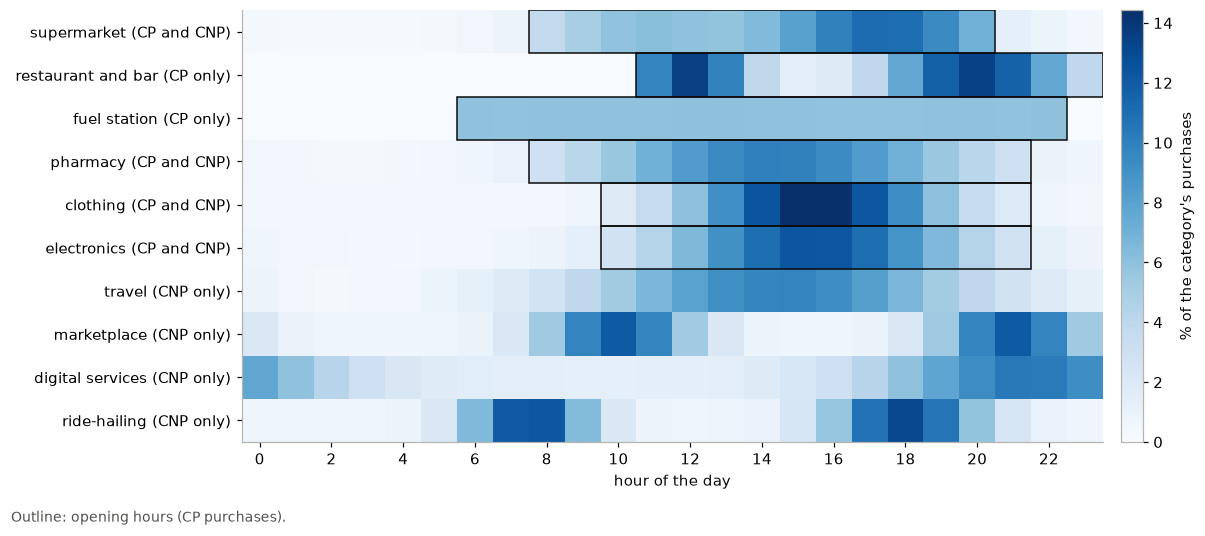

In [5]:
hour = (transactions.TX_TIME_SECONDS % 86400) // 3600
table = pd.crosstab(transactions.MERCHANT_CATEGORY, hour, normalize="index").reindex(
    index=list(CATEGORIES), columns=range(24), fill_value=0
)
fig, ax = plt.subplots(figsize=(11, 4.8))
image = ax.imshow(100 * table.to_numpy(), aspect="auto", cmap="Blues", vmin=0)
for i, name in enumerate(table.index):
    category = CATEGORIES[name]
    if category.has_cp:
        start, stop = category.opening_hours
        ax.add_patch(plt.Rectangle((start - 0.5, i - 0.5), stop - start, 1, fill=False,
                                   edgecolor=INK, lw=1))
ax.set_yticks(range(len(table)), [f"{LABELS[n]} ({CHANNEL_LABELS[CATEGORIES[n].channel]})"
                                  for n in table.index])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel(T["hour_of_day"])
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
colorbar.set_label(T["share_of_category"])
fig.text(0.01, 0.0, T["opening_note"], fontsize=9, color=SECONDARY)
fig.tight_layout(rect=(0, 0.03, 1, 1))
localize(fig)
fig.savefig(FIG_DIR / "merchants_hour_by_category.pdf", bbox_inches="tight")
plt.show()

## Share of the categories

Share of the purchases in each category, split into CP and CNP, compared with the configured
weight (tick); in mixed categories, the label also shows the CNP share.

- **CP-only categories below their weight.** A customer with no merchant of the category in
  reach (10 km) does not buy in it, and their preference is redistributed among the other
  categories.
- **Mixed categories.** A customer buys online with probability
  $\sigma(c_k + \mathrm{logit}(p_{\text{customer}}))$, where $c_k$ is chosen so that the
  mean, with a uniform `cnp_prob`, is the online fraction of the category (supermarket 0.10;
  pharmacy 0.15; clothing 0.30; electronics 0.50). Whoever has no merchant of the category
  in reach always buys online, so the CNP share of the whole category is above the base.

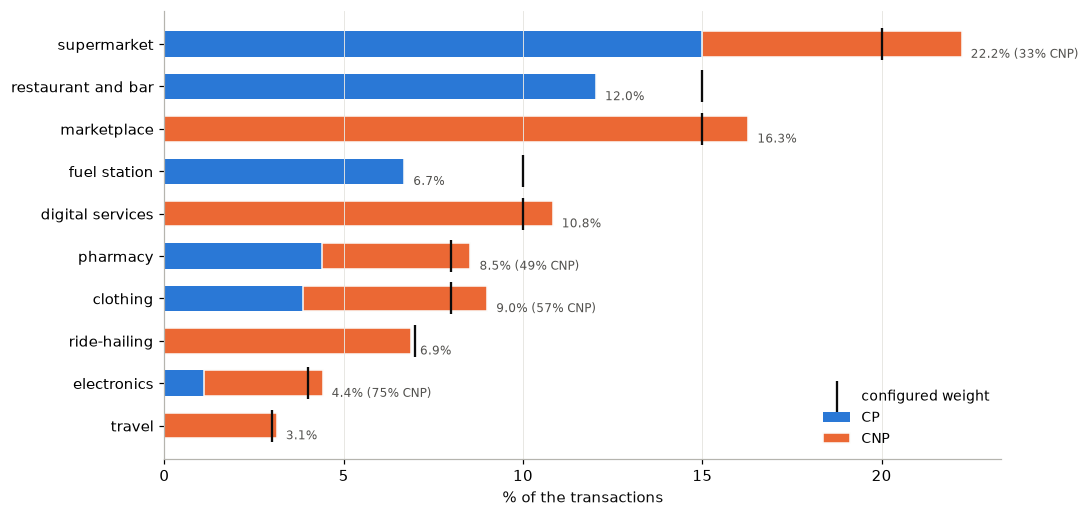

customers without a terminal in reach: 7.1%; terminals in reach, median: 14


,customers without a merchant in reach,CNP (all),CNP (customers with a merchant in reach),online fraction
category,,,,
supermercado,22.2%,32.5%,10.2%,0.10
restaurante_bar,26.1%,0.0%,0.0%,NaN
posto_combustivel,32.3%,0.0%,0.0%,NaN
farmacia,35.7%,48.6%,15.4%,0.15
vestuario,34.5%,57.1%,30.7%,0.30
eletronicos,47.2%,74.9%,50.1%,0.50


In [6]:
share = pd.crosstab(transactions.MERCHANT_CATEGORY, transactions.TX_TYPE, normalize="all")
share = share.reindex(index=sorted(CATEGORIES, key=lambda n: -CATEGORIES[n].weight), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(share))[::-1]
ax.barh(y, 100 * share["CP"], color=CHANNEL_COLORS["CP"], height=0.6, label="CP")
ax.barh(y, 100 * share["CNP"], left=100 * share["CP"], color=CHANNEL_COLORS["CNP"], height=0.6,
        label="CNP", edgecolor="#fcfcfb", lw=1)
weights = np.array([CATEGORIES[n].weight for n in share.index])
ax.scatter(100 * weights, y, marker="|", s=420, color=INK, lw=1.5, label=T["configured_weight"], zorder=3)
cnp_within = share["CNP"] / share.sum(axis=1)
for yi, name, total in zip(y, share.index, 100 * share.sum(axis=1)):
    label = f"{total:.1f}%"
    if CATEGORIES[name].channel == "CP+CNP":
        label += f" ({100 * cnp_within[name]:.0f}% CNP)"
    ax.annotate(num(label), (total, yi), xytext=(6, -9), textcoords="offset points",
                fontsize=8, color=SECONDARY)
ax.set_yticks(y, [LABELS[n] for n in share.index])
ax.set_xlabel(T["share_of_tx"])
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "merchants_category_share.pdf", bbox_inches="tight")
plt.show()

reach = customers.available_terminals.apply(len)
print(f"customers without a terminal in reach: {(reach == 0).mean():.1%}; "
      f"terminals in reach, median: {reach.median():.0f}")

# By category: customers without a merchant of it in reach and, among those who reach
# one, the share of online purchases (mixed categories: close to the online fraction)
terminal_category = terminals.MERCHANT_ID.map(merchants.MERCHANT_CATEGORY).to_numpy()
rows = []
for name, category in CATEGORIES.items():
    if not category.has_cp:
        continue
    reaches = customers.available_terminals.map(
        lambda t, name=name: bool((terminal_category[t] == name).any())
    )
    tx = transactions[transactions.MERCHANT_CATEGORY == name]
    near = tx[tx.CUSTOMER_ID.isin(customers.CUSTOMER_ID[reaches])]
    rows.append({
        "category": name,
        "customers without a merchant in reach": f"{1 - reaches.mean():.1%}",
        "CNP (all)": f"{(tx.TX_TYPE == 'CNP').mean():.1%}",
        "CNP (customers with a merchant in reach)": f"{(near.TX_TYPE == 'CNP').mean():.1%}",
        "online fraction": category.online_fraction if category.channel == "CP+CNP" else None,
    })
pd.DataFrame(rows).set_index("category")

## Loyalty

With `loyalty=0.6`, each customer goes back to their favourite merchants of each category.
Share of each customer's purchases, in a category, made at the two merchants where they buy
the most.

In [7]:
counts = transactions.groupby(["CUSTOMER_ID", "MERCHANT_CATEGORY", "MERCHANT_ID"]).size()
groups = counts.groupby(level=[0, 1])
top2 = (groups.apply(lambda s: s.nlargest(2).sum()) / groups.sum())[groups.sum() >= 10]
top2.groupby(level=1).mean().rename(lambda n: LABELS[n]).round(2).to_frame("share at the 2 favourites")

,share at the 2 favourites
MERCHANT_CATEGORY,
marketplace,0.70
electronics,0.66
pharmacy,0.71
fuel station,0.80
restaurant and bar,0.79
digital services,0.70
supermarket,0.71
ride-hailing,0.70
clothing,0.68
